Tutorial: topology optimisation using pyfe3d
===

Date: 14 of October 2024

Author: Saullo G. P. Castro

Cite this tutorial as:

Castro, SGP (2026). General-purpose finite element solver based on Python and Cython (Version 0.7.0). Zenodo. DOI: https://doi.org/10.5281/zenodo.6573489.

TODO(author): this record version (0.7.0) differs from the current pyfe3d version (0.12.0) and the date (2024) from the citation year (2026); confirm what to cite.


Importing Python modules
---

The material distribution of a square membrane is optimised to minimise its compliance under a
point load, for a prescribed fraction of the material, with a density-based approach and the
gradient-based SLSQP algorithm of `scipy`.

TODO(author): give the reference for the density (power-law) approach to topology optimisation.

In [1]:
%matplotlib inline
import numpy as np
from numpy import isclose
import matplotlib.pyplot as plt
from scipy.sparse.linalg import cg
from scipy.sparse import coo_matrix
from scipy.optimize import minimize

from pyfe3d.shellprop_utils import isotropic_plate
from pyfe3d import Quad4R, Quad4RData, Quad4RProbe, INT, DOUBLE, DOF

Creating mesh
---

A $3 \times 3$ m steel plate, 3 mm thick, meshed with $39 \times 39$ nodes, i.e. $38 \times 38$
`Quad4R` elements. Each element has one design variable, its density $\rho_i$.

In [2]:
data = Quad4RData()
probe = Quad4RProbe()
nx = 39
ny = 39
N = DOF*nx*ny

a = 3.0
b = 3.0

c = 3
E0 = 203.e9 # Pa
nu = 0.33

h = 0.003 # m

xtmp = np.linspace(0, a, nx)
ytmp = np.linspace(0, b, ny)
xmesh, ymesh = np.meshgrid(xtmp, ytmp)
ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(), np.zeros_like(ymesh.T.flatten()))).T

x = ncoords[:, 0]
y = ncoords[:, 1]
z = ncoords[:, 2]
ncoords_flatten = ncoords.flatten()

nids = 1 + np.arange(ncoords.shape[0])
nid_pos = dict(zip(nids, np.arange(len(nids))))
nids_mesh = nids.reshape(nx, ny)
n1s = nids_mesh[:-1, :-1].flatten()
n2s = nids_mesh[1:, :-1].flatten()
n3s = nids_mesh[1:, 1:].flatten()
n4s = nids_mesh[:-1, 1:].flatten()

num_elements = len(n1s)
print('# number of elements', num_elements)

nodes = list(zip(n1s, n2s, n3s, n4s))


# number of elements 1444


Calculate the stiffness matrix for a vector of design variables "rho"
---

The Young modulus of every element follows the power law $E_i = \rho_i^c E_0$, where $E_0$ is the
Young modulus of the solid material and the exponent $c = 3$ penalises intermediate densities,
which then give little stiffness for their volume and are driven towards 0 or 1.

In [3]:
def calc_K(rho):
    E = rho**c*E0

    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)

    quads = []
    init_k_KC0 = 0
    i = 0
    for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
        prop = isotropic_plate(thickness=h, E=E[i], nu=nu)
        i += 1
        pos1 = nid_pos[n1]
        pos2 = nid_pos[n2]
        pos3 = nid_pos[n3]
        pos4 = nid_pos[n4]
        r1 = ncoords[pos1]
        r2 = ncoords[pos2]
        r3 = ncoords[pos3]
        quad = Quad4R(probe)
        quad.n1 = n1
        quad.n2 = n2
        quad.n3 = n3
        quad.n4 = n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = init_k_KC0
        quad.update_rotation_matrix(ncoords_flatten)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quads.append(quad)
        init_k_KC0 += data.KC0_SPARSE_SIZE

    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()

    return KC0


Sensitivity of the stiffness matrix with respect to the vector "rho"
---

Each $\rho_i$ affects only the stiffness matrix of element $i$, which is linear in $E_i$, so

$$\frac{\partial \mathbf{K}}{\partial \rho_i} = \mathbf{K}_i\left(\frac{\partial E_i}{\partial \rho_i}\right), \qquad
\frac{\partial E_i}{\partial \rho_i} = c \rho_i^{c-1} E_0$$

where $\mathbf{K}_i(E)$ is the stiffness matrix of element $i$ alone, assembled with the modulus
$E$. The function below returns it.

In [4]:
def K_rho(rho, i):
    E_rho = c*rho[i]**(c-1)*E0
    prop = isotropic_plate(thickness=h, E=E_rho, nu=nu)

    KC0r = np.zeros(1*data.KC0_SPARSE_SIZE, dtype=INT)
    KC0c = np.zeros(1*data.KC0_SPARSE_SIZE, dtype=INT)
    KC0v = np.zeros(1*data.KC0_SPARSE_SIZE, dtype=DOUBLE)

    n1, n2, n3, n4 = nodes[i]
    pos1 = nid_pos[n1]
    pos2 = nid_pos[n2]
    pos3 = nid_pos[n3]
    pos4 = nid_pos[n4]
    r1 = ncoords[pos1]
    r2 = ncoords[pos2]
    r3 = ncoords[pos3]
    quad = Quad4R(probe)
    quad.n1 = n1
    quad.n2 = n2
    quad.n3 = n3
    quad.n4 = n4
    quad.c1 = DOF*nid_pos[n1]
    quad.c2 = DOF*nid_pos[n2]
    quad.c3 = DOF*nid_pos[n3]
    quad.c4 = DOF*nid_pos[n4]
    quad.init_k_KC0 = 0
    quad.update_rotation_matrix(ncoords_flatten)
    quad.update_probe_xe(ncoords_flatten)
    quad.update_KC0(KC0r, KC0c, KC0v, prop)

    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()

    return KC0



Applying boundary conditions and forces
---

The in-plane displacements $u$, $v$ are zero at the two corners at $x = 0$, $(0, 0)$ and $(0, b)$.
The out-of-plane displacement $w$ and the rotations about $x$ and $y$ are restrained at all
nodes, making it a two-dimensional membrane problem. A point force of $-1000$ N along $y$ acts at
the corner $(a, 0)$.

In [5]:
bk = np.zeros(N, dtype=bool)
check = isclose(x, 0) & (isclose(y, 0.) | isclose(y, b))
bk[0::DOF] = check
bk[1::DOF] = check
# making it a 2D membrane problem
bk[2::DOF] = True
bk[3::DOF] = True
bk[4::DOF] = True

bu = ~bk

# point load along v at the corner (a, 0)
fext = np.zeros(N)
ftotal = -1000.
print('ftotal', ftotal)
check = isclose(x, a) & isclose(y, 0)
fext[1::DOF][check] = ftotal


ftotal -1000.0


Performing topology optimization
---

The compliance $C = \mathbf{u}^T \mathbf{K} \mathbf{u}$, with $\mathbf{K}\mathbf{u} = \mathbf{f}$, is
minimised subject to the volume fraction $\sum_i \rho_i / n \le 0.4$ and the bounds
$10^{-6} \le \rho_i \le 1$. The lower bound keeps the stiffness matrix non-singular. The static
problem is solved with the conjugate gradient method on the diagonally scaled system.

Since the load does not depend on $\rho$, the adjoint method gives the gradient without further
solutions:

$$\frac{\partial C}{\partial \rho_i} = -\mathbf{u}^T \frac{\partial \mathbf{K}}{\partial \rho_i} \mathbf{u}$$

The function `jac` uses the displacements of the last call to `objective`, which SLSQP evaluates
at the same design before it asks for the gradient. The start design is the full plate,
$\rho_i = 1$; every call to `objective` prints the compliance.

In [6]:
uu = None
K = None

def jac(rho):
    """Adjoint gradient of the compliance with respect to each density in 'rho'
    """
    u = np.zeros(N)
    u[bu] = uu
    C_rho = np.zeros(num_elements)
    for i in range(num_elements):
        C_rho[i] = - u.T @ K_rho(rho, i) @ u
    return C_rho


def rel_volume(rho):
    target_rel_volume = 0.4
    constr = target_rel_volume - np.sum(rho)/num_elements
    return constr


def objective(rho):
    global uu, K
    K = calc_K(rho)
    Kuu = K[bu, :][:, bu]
    PREC = np.max(1/Kuu.diagonal())
    uu, info = cg(PREC*Kuu, PREC*fext[bu], atol=1e-3)
    compl = uu.T @ Kuu @ uu
    print('compliance', compl)
    return compl


constraints = [
    {'type': 'ineq', 'fun': rel_volume},
]
bounds = [[1.e-6, 1.] for _ in range(num_elements)]

rho = np.ones(num_elements)
topopt = minimize(objective, rho, jac=jac, method='SLSQP',
               constraints=constraints, bounds=bounds)

compliance 0.03383225280019338


compliance 0.550820821357927


compliance 0.3505638968840433


compliance 0.32130668356894426


compliance 0.26043922507979655


compliance 0.24492970799217506


... (91 outputs left out)

compliance 0.060657581573009406


compliance 0.0604235297845178


compliance 0.06021782837385118


compliance 0.05999268887479371


Checking the result of the topology optimization
---

The final compliance and volume fraction are printed, and the density of each element is plotted
at its centroid.

success: False - Iteration limit reached
iterations: 100
final compliance: 0.05999268887479371
volume fraction: 0.3999999999999999
fraction of elements with rho > 0.9: 0.1731301939058172
fraction of elements with rho < 0.1: 0.389196675900277


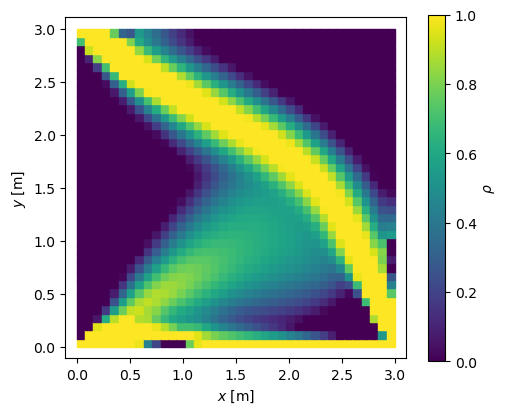

In [7]:
print('success:', topopt.success, '-', topopt.message)
print('iterations:', topopt.nit)
print('final compliance:', topopt.fun)
print('volume fraction:', np.sum(topopt.x)/num_elements)
print('fraction of elements with rho > 0.9:', np.mean(topopt.x > 0.9))
print('fraction of elements with rho < 0.1:', np.mean(topopt.x < 0.1))

xcg = np.zeros((num_elements, 3))
i = 0
for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
    pos1 = nid_pos[n1]
    pos2 = nid_pos[n2]
    pos3 = nid_pos[n3]
    pos4 = nid_pos[n4]
    r1 = ncoords[pos1]
    r2 = ncoords[pos2]
    r3 = ncoords[pos3]
    r4 = ncoords[pos4]

    xcg[i] = (r1 + r2 + r3 + r4)/4
    i += 1

plt.figure(figsize=(5.5, 4.5))
plt.scatter(xcg[:, 0], xcg[:, 1], c=topopt.x, vmin=0, vmax=1, marker='s')
plt.colorbar(label=r'$\rho$')
plt.gca().set_aspect('equal')
plt.xlabel('$x$ [m]')
plt.ylabel('$y$ [m]')
plt.show()